# Stage 8: Interpretability (finsent-lora-interp)
 Main model = `adapter_r16_lr2e-4`.

Three checks:
- **(a) Layer drift:** how much each layer's final-token hidden state changed after fine-tuning (cosine similarity, base vs fine-tuned).
- **(b) Linear probes:** at which layer is sentiment linearly decodable, base vs fine-tuned.
- **(c) LoRA update size:** norm of (alpha/r)*B*A per layer and module.


In [1]:
!pip install -q transformers datasets peft bitsandbytes accelerate scikit-learn matplotlib pandas
from huggingface_hub import login
login()
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
import torch, json, os, re, gc, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
from peft import PeftModel

BASE = "meta-llama/Llama-3.2-3B-Instruct"
DRIVE = "/content/drive/MyDrive/finsent"
ADAPTER = f"{DRIVE}/adapter_r16_lr2e-4"
assert os.path.isdir(ADAPTER)
SEED = 42

tok = AutoTokenizer.from_pretrained(BASE)
tok.pad_token = tok.eos_token
tok.padding_side = "left"          # last position = final prompt token

bnb = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4",
                         bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=torch.float16)
base = AutoModelForCausalLM.from_pretrained(BASE, quantization_config=bnb,
                                            device_map={"": 0}, dtype=torch.float16)
model = PeftModel.from_pretrained(base, ADAPTER)
model.eval()

ds = load_dataset("zeroshot/twitter-financial-news-sentiment")
label_words = ["Bearish", "Bullish", "Neutral"]

PROMPT_DATE = "01 Jan 2026"
def build_prompt(text):
    msgs = [{"role": "system", "content": "You are a financial sentiment classifier."},
            {"role": "user", "content": f"Classify the sentiment of this finance tweet as exactly one of: {', '.join(label_words)}.\n\nTweet: {text}\n\nAnswer with one word."}]
    return tok.apply_chat_template(msgs, tokenize=False, add_generation_prompt=True, date_string=PROMPT_DATE)
print(build_prompt("test")[:120])   # must show Today Date: 01 Jan 2026

# fixed subsets (seed 42)
rng = np.random.RandomState(SEED)
tr_idx = rng.choice(len(ds["train"]), 2000, replace=False)
va_idx = rng.choice(len(ds["validation"]), 1000, replace=False)
tr_texts = [ds["train"][int(i)]["text"] for i in tr_idx]
tr_y = np.array([ds["train"][int(i)]["label"] for i in tr_idx])
va_texts = [ds["validation"][int(i)]["text"] for i in va_idx]
va_y = np.array([ds["validation"][int(i)]["label"] for i in va_idx])
print(len(tr_texts), len(va_texts), np.bincount(tr_y), np.bincount(va_y))

Loading weights:   0%|          | 0/254 [00:00<?, ?it/s]

<|begin_of_text|><|start_header_id|>system<|end_header_id|>

Cutting Knowledge Date: December 2023
Today Date: 01 Jan 20
2000 1000 [ 299  412 1289] [158 189 653]


In [4]:
# Final-token hidden state at every layer (index 0 = embeddings, 1..28 = decoder layers; last one is after final norm)
@torch.no_grad()
def hidden(texts, bs=16):
    out_all = []
    for i in tqdm(range(0, len(texts), bs)):
        enc = tok([build_prompt(t) for t in texts[i:i+bs]], return_tensors="pt",
                  padding=True, add_special_tokens=False).to(model.device)
        hs = model(**enc, output_hidden_states=True).hidden_states
        out_all.append(torch.stack([h[:, -1, :] for h in hs], dim=1).float().cpu().numpy().astype(np.float16))
    return np.concatenate(out_all)       # (N, 29, 3072)

print("fine-tuned: train subset"); H_ft_tr = hidden(tr_texts)
print("fine-tuned: val subset");   H_ft_va = hidden(va_texts)
with model.disable_adapter():
    print("base: train subset"); H_bs_tr = hidden(tr_texts)
    print("base: val subset");   H_bs_va = hidden(va_texts)
print(H_ft_tr.shape, H_ft_va.shape)

fine-tuned: train subset


  0%|          | 0/125 [00:00<?, ?it/s]

fine-tuned: val subset


  0%|          | 0/63 [00:00<?, ?it/s]

base: train subset


  0%|          | 0/125 [00:00<?, ?it/s]

base: val subset


  0%|          | 0/63 [00:00<?, ?it/s]

(2000, 29, 3072) (1000, 29, 3072)


 layer  cos_mean  cos_std  cos_min
     0    1.0000   0.0000   1.0000
     1    0.9976   0.0001   0.9974
     2    0.9963   0.0001   0.9958
     3    0.9951   0.0002   0.9947
     4    0.9893   0.0004   0.9882
     5    0.9596   0.0025   0.9503
     6    0.9351   0.0038   0.9243
     7    0.9164   0.0033   0.9041
     8    0.9026   0.0030   0.8936
     9    0.8536   0.0045   0.8426
    10    0.8084   0.0082   0.7893
    11    0.7354   0.0102   0.7131
    12    0.7304   0.0122   0.6868
    13    0.6912   0.0202   0.5945
    14    0.7060   0.0383   0.5645
    15    0.7031   0.0419   0.5585
    16    0.6983   0.0672   0.5205
    17    0.7014   0.0750   0.4899
    18    0.7105   0.0612   0.5352
    19    0.7097   0.0641   0.5304
    20    0.7278   0.0650   0.4931
    21    0.7670   0.0630   0.5383
    22    0.7677   0.0654   0.5146
    23    0.7891   0.0606   0.5612
    24    0.7972   0.0558   0.5900
    25    0.8077   0.0543   0.6132
    26    0.8136   0.0527   0.6272
    27    0.8086   0

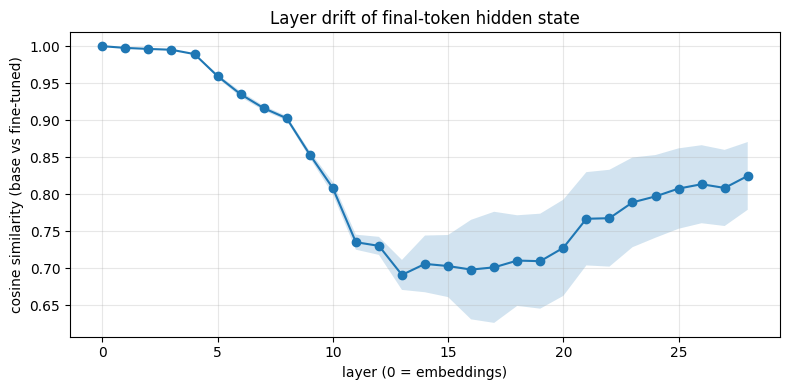

In [5]:
# (a) Layer drift: cosine similarity base vs fine-tuned, first 500 validation tweets
a = H_bs_va[:500].astype(np.float32); b = H_ft_va[:500].astype(np.float32)
cos = (a*b).sum(-1) / (np.linalg.norm(a, axis=-1) * np.linalg.norm(b, axis=-1) + 1e-8)   # (500, 29)
drift = pd.DataFrame({"layer": range(cos.shape[1]), "cos_mean": cos.mean(0), "cos_std": cos.std(0), "cos_min": cos.min(0)})
print(drift.round(4).to_string(index=False))
assert drift.cos_mean[0] > 0.999, "layer 0 (embeddings) should be identical; check setup"

plt.figure(figsize=(8,4))
plt.plot(drift.layer, drift.cos_mean, marker="o"); plt.fill_between(drift.layer, drift.cos_mean-drift.cos_std, drift.cos_mean+drift.cos_std, alpha=0.2)
plt.xlabel("layer (0 = embeddings)"); plt.ylabel("cosine similarity (base vs fine-tuned)")
plt.title("Layer drift of final-token hidden state"); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"{DRIVE}/fig_layer_drift.png", dpi=150); plt.show()
drift.to_csv(f"{DRIVE}/layer_drift.csv", index=False)

  0%|          | 0/29 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _c

  0%|          | 0/29 [00:00<?, ?it/s]

 layer  macro_f1_base  acc_base  macro_f1_ft  acc_ft
     0         0.2634     0.653       0.2634   0.653
     1         0.5793     0.701       0.5751   0.702
     2         0.6241     0.736       0.6182   0.729
     3         0.6386     0.755       0.6372   0.754
     4         0.6353     0.748       0.6478   0.752
     5         0.6769     0.773       0.7015   0.787
     6         0.6920     0.779       0.7232   0.798
     7         0.6921     0.779       0.7657   0.827
     8         0.7308     0.804       0.7965   0.845
     9         0.7547     0.821       0.8196   0.861
    10         0.7547     0.815       0.8554   0.885
    11         0.7794     0.835       0.8732   0.899
    12         0.7956     0.840       0.8805   0.906
    13         0.8157     0.856       0.8814   0.905
    14         0.8347     0.869       0.8816   0.905
    15         0.8519     0.879       0.8811   0.905
    16         0.8452     0.875       0.8853   0.909
    17         0.8363     0.870       0.8851  

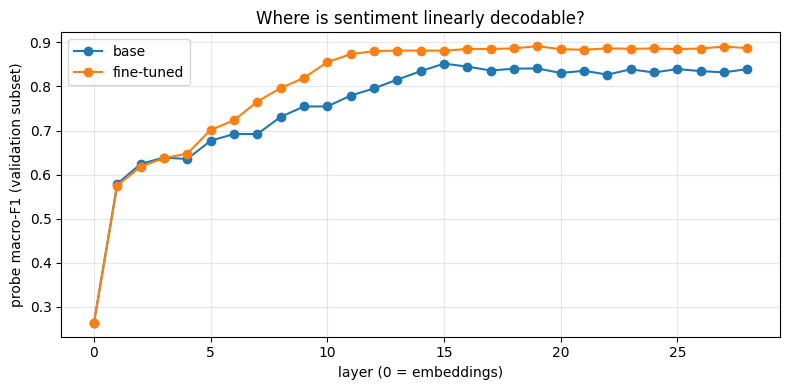

In [6]:
# (b) Linear probes: fit on TRAIN-subset hidden states, test on VALIDATION-subset
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import f1_score, accuracy_score

def probe_scores(Htr, Hva):
    rows = []
    for l in tqdm(range(Htr.shape[1])):
        sc = StandardScaler().fit(Htr[:, l].astype(np.float32))
        clf = LogisticRegression(C=0.05, max_iter=300).fit(sc.transform(Htr[:, l].astype(np.float32)), tr_y)
        p = clf.predict(sc.transform(Hva[:, l].astype(np.float32)))
        rows.append((l, f1_score(va_y, p, average="macro"), accuracy_score(va_y, p)))
    return pd.DataFrame(rows, columns=["layer", "macro_f1", "acc"])

pb_base = probe_scores(H_bs_tr, H_bs_va)
pb_ft = probe_scores(H_ft_tr, H_ft_va)
probe = pb_base.merge(pb_ft, on="layer", suffixes=("_base", "_ft"))
print(probe.round(4).to_string(index=False))

plt.figure(figsize=(8,4))
plt.plot(probe.layer, probe.macro_f1_base, marker="o", label="base")
plt.plot(probe.layer, probe.macro_f1_ft, marker="o", label="fine-tuned")
plt.xlabel("layer (0 = embeddings)"); plt.ylabel("probe macro-F1 (validation subset)")
plt.title("Where is sentiment linearly decodable?"); plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"{DRIVE}/fig_probes.png", dpi=150); plt.show()
probe.to_csv(f"{DRIVE}/probe_results.csv", index=False)

module  q_proj  k_proj  v_proj  o_proj  gate_proj  up_proj  down_proj
layer                                                                
0        1.274   0.837   0.601   1.099      1.784    1.835      1.376
1        1.189   0.649   0.646   1.066      1.904    1.869      1.615
2        1.082   0.627   0.614   1.077      1.899    1.819      1.380
3        1.370   0.667   0.616   1.022      1.890    1.709      1.317
4        1.115   0.590   0.647   0.979      1.929    1.704      1.280
5        1.275   0.703   0.543   0.928      2.003    1.716      1.430
6        1.191   0.737   0.550   0.991      2.097    1.588      1.335
7        1.228   0.774   0.539   0.938      2.118    1.564      1.287
8        1.174   0.708   0.542   0.865      1.797    1.558      1.263
9        1.061   0.813   0.596   0.925      1.979    1.574      1.061
10       1.051   0.584   0.554   0.828      1.625    1.430      0.931
11       1.023   0.654   0.521   0.843      1.488    1.337      0.863
12       0.834   0.5

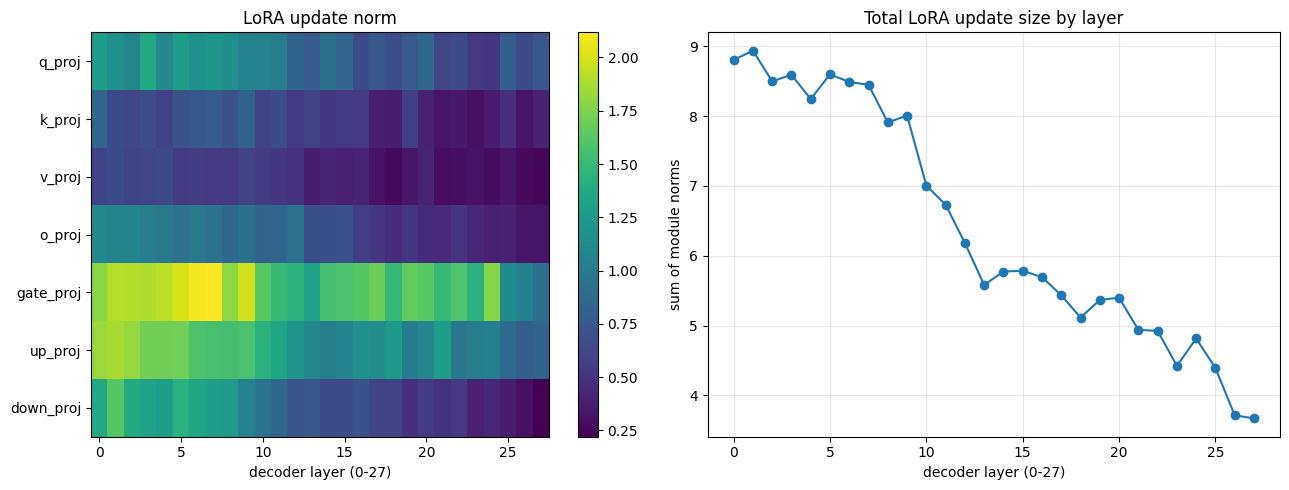

In [7]:
# (c) LoRA update size per layer and module: ||(alpha/r) * B @ A||_F, via ||BA||_F^2 = sum((B^T B) * (A A^T))
rows = []
for name, mod in model.named_modules():
    if hasattr(mod, "lora_A") and "default" in getattr(mod, "lora_A", {}):
        A = mod.lora_A["default"].weight.float()       # (r, in)
        B = mod.lora_B["default"].weight.float()       # (out, r)
        s = mod.scaling["default"]                     # alpha / r
        fro = (s**2 * ((B.T @ B) * (A @ A.T)).sum()).sqrt().item()
        m = re.search(r"layers\.(\d+)\.(.+)$", name)
        rows.append((int(m.group(1)), m.group(2).split(".")[-1], fro))
lora = pd.DataFrame(rows, columns=["layer", "module", "norm"])
piv = lora.pivot(index="layer", columns="module", values="norm")[["q_proj","k_proj","v_proj","o_proj","gate_proj","up_proj","down_proj"]]
print(piv.round(3).to_string())
print("\nmean over layers per module:\n", piv.mean().round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(13,5))
im = ax[0].imshow(piv.values.T, aspect="auto", cmap="viridis")
ax[0].set_yticks(range(7)); ax[0].set_yticklabels(piv.columns); ax[0].set_xlabel("decoder layer (0-27)")
ax[0].set_title("LoRA update norm"); plt.colorbar(im, ax=ax[0])
ax[1].plot(piv.index, piv.sum(1), marker="o"); ax[1].set_xlabel("decoder layer (0-27)")
ax[1].set_ylabel("sum of module norms"); ax[1].set_title("Total LoRA update size by layer"); ax[1].grid(alpha=0.3)
plt.tight_layout(); plt.savefig(f"{DRIVE}/fig_lora_norms.png", dpi=150); plt.show()
piv.to_csv(f"{DRIVE}/lora_update_norms.csv")

In [8]:
# Summary (report as found; correlational, one model, one task, one seed)
d = drift.iloc[1:]   # skip embeddings
summary = {
  "drift_min_cos_layer": int(d.loc[d.cos_mean.idxmin(), "layer"]), "drift_min_cos": float(d.cos_mean.min()),
  "drift_final_layer_cos": float(drift.cos_mean.iloc[-1]),
  "probe_best_base": {"layer": int(probe.loc[probe.macro_f1_base.idxmax(), "layer"]), "macro_f1": float(probe.macro_f1_base.max())},
  "probe_best_ft":   {"layer": int(probe.loc[probe.macro_f1_ft.idxmax(), "layer"]),   "macro_f1": float(probe.macro_f1_ft.max())},
  "lora_largest_total_layer": int(piv.sum(1).idxmax()),
  "lora_largest_module_mean": str(piv.mean().idxmax()),
}
for thr in (0.6, 0.7, 0.8):
    for k in ("base", "ft"):
        hit = probe[probe[f"macro_f1_{k}"] >= thr]
        summary[f"first_layer_probe_{k}_ge_{thr}"] = int(hit.layer.iloc[0]) if len(hit) else None
print(json.dumps(summary, indent=2))
json.dump(summary, open(f"{DRIVE}/interp_summary.json", "w"), indent=2)
print("saved: layer_drift.csv, probe_results.csv, lora_update_norms.csv, interp_summary.json, 3 figures")

{
  "drift_min_cos_layer": 13,
  "drift_min_cos": 0.6911661028862,
  "drift_final_layer_cos": 0.8248286843299866,
  "probe_best_base": {
    "layer": 15,
    "macro_f1": 0.8518937440884522
  },
  "probe_best_ft": {
    "layer": 19,
    "macro_f1": 0.8915347014889491
  },
  "lora_largest_total_layer": 1,
  "lora_largest_module_mean": "gate_proj",
  "first_layer_probe_base_ge_0.6": 2,
  "first_layer_probe_ft_ge_0.6": 2,
  "first_layer_probe_base_ge_0.7": 8,
  "first_layer_probe_ft_ge_0.7": 5,
  "first_layer_probe_base_ge_0.8": 13,
  "first_layer_probe_ft_ge_0.8": 9
}
saved: layer_drift.csv, probe_results.csv, lora_update_norms.csv, interp_summary.json, 3 figures
